# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [52]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [54]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [55]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [56]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [57]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [58]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [59]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [60]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [61]:

# cantidad de nulos para users
print(users.isna().sum())  # Cantidad de valores nulos
print(users.isna().mean()) # Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [62]:
# cantidad de nulos para usage
print(usage.isna().sum())  # Cantidad de valores nulos
print(usage.isna().mean()) # Proporción de valores nulos


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

Al revisar los datos de usage, encontré que hay tres columnas con valores faltantes:

date tiene 50 valores nulos, que representan el 0.125%.

duration tiene 22,076 valores nulos, que representan el 55.19%.

length tiene 17,896 valores nulos, que representan el 44.74%.

En el caso de date, como son pocos registros y no sabemos cuáles eran las fechas correctas, yo consideraría eliminarlos si necesitamos esa información para el análisis.

En cuanto a duration y length, creo que lo mejor sería dejar los valores nulos como están, porque duration corresponde a las llamadas y length a los mensajes. Entonces, tiene sentido que algunos registros no tengan información en ambas columnas.

Por eso, mi recomendación sería ignorar esos valores nulos, sin rellenarlos ni eliminar los registros, ya que podríamos perder información que nos puede servir más adelante.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [63]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` identifica a cada cliente. Es importante revisar que los identificadores sean consistentes para poder relacionar correctamente las tablas.

- La columna `age` contiene las edades de los clientes. Encontré valores de `-999`, que no representan edades reales, por lo que necesitan corregirse antes del análisis.

In [64]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Las columnas id y user_id contienen identificadores. La primera identifica cada registro de uso y la segunda permite relacionarlo con un cliente.

Las columnas duration y length tienen valores faltantes. Esto se debe en gran parte a que las llamadas registran duración y los mensajes registran longitud, por lo que no todos los registros necesitan tener información en ambas columnas.

In [65]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(f"\nColumna: {columna}")
    print(users[columna].value_counts(dropna=False))



Columna: city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Columna: plan
Basico     2595
Premium    1405
Name: plan, dtype: int64


La columna city contiene algunas ciudades registradas como ?. Estos valores no representan una ciudad válida, por lo que los cambiaría por valores nulos.

La columna plan permite identificar qué plan tiene cada cliente. Encontré dos categorías: Básico y Premium, que podemos utilizar para comparar el comportamiento de los usuarios.

In [66]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

La columna type identifica el tipo de actividad registrada por cada usuario, ya sea una llamada o un mensaje. Esta información nos permite analizar ambos tipos de uso por separado.


✍️ Comentario: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías par

a cada caso.

Valores inválidos o sentinels

¿En qué columnas encontraste valores inválidos o sentinels?
¿Qué acción tomarías?

Al revisar los datos, encontré algunos valores que no son válidos:

En la columna age aparece el valor -999, que no puede ser una edad real. Considero que lo mejor es reemplazarlo por la mediana de las edades válidas para no afectar el análisis.

En la columna city aparece el símbolo "?", lo que significa que no sabemos a qué ciudad pertenece el usuario. En este caso, lo reemplazaría por un valor nulo (pd.NA), ya que no tenemos información para saber cuál es la ciudad correcta.

Mi recomendación es corregir estos valores antes de continuar con el análisis, para trabajar con datos más confiables sin eliminar registros innecesariamente.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [67]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [68]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [69]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

Al revisar las fechas de registro, encontré que hay 1,314 registros de 2022, 1,316 de 2023 y 1,330 de 2024. También aparecen 40 registros de 2026, que están fuera del periodo que estamos analizando.

In [70]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64

En esta columna encontré 39,950 registros del año 2024 y 50 valores nulos. 
Esto significa que hay 50 registros en los que no tenemos una fecha válida.
    

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

Al revisar las fechas, encontré que en reg_date hay 40 registros del año 2026, pero los datos que estamos analizando llegan hasta 2024. Entonces, esas fechas no corresponden al periodo del análisis.

En usage, encontré que las fechas son de 2024, aunque también hay 50 registros que no tienen fecha.

Yo cambiaría las fechas de 2026 por valores nulos, porque realmente no sabemos cuáles eran las fechas correctas. Y en el caso de los 50 registros sin fecha, primero revisaría si nos afectan en el análisis antes de decidir si los eliminamos.

Creo que así podemos trabajar con datos más confiables sin tener que borrar información que todavía nos puede servir.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [71]:
# Recuperar los datos originales de usuarios
users = pd.read_csv('/datasets/users_latam.csv')

# Calcular la mediana excluyendo -999
age_mediana = users.loc[users['age'] != -999, 'age'].median()

# Reemplazar -999 por la mediana
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar los resultados
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [72]:
# Recuperar los datos originales
users = pd.read_csv('/datasets/users_latam.csv')

# Calcular la mediana excluyendo -999
age_mediana = users.loc[users['age'] != -999, 'age'].median()

# Reemplazar -999 por la mediana
users['age'] = users['age'].replace(-999, age_mediana)

# Reemplazar los signos ? de city por valores nulos
users['city'] = users['city'].replace('?', pd.NA)

# Verificar los resultados
print("Edades:")
print(users['age'].describe())

print("\nValores ? que quedan en city:")
print((users['city'] == '?').sum())

print("\nValores nulos en city:")
print(users['city'].isna().sum())

Edades:
count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

Valores ? que quedan en city:
0

Valores nulos en city:
565


In [73]:
# Convertir reg_date a formato de fecha
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# Marcar fechas posteriores a 2024 como nulas
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

In [74]:
# Convertir las columnas a formato de fecha
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

# Marcar las fechas posteriores a 2024 como nulas
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Revisar los resultados
print("Fechas de registro por año:")
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

print("\nFechas de uso nulas:")
print(usage['date'].isna().sum())

Fechas de registro por año:
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

Fechas de uso nulas:
50


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [75]:
# Verificación MAR en usage (Missing At Random) para duration
pd.crosstab(usage['type'], usage['duration'].isna())


duration,False,True
type,,
call,17908,0
text,16,22076


In [76]:
# Verificación MAR en usage (Missing At Random) para length
pd.crosstab(usage['type'], usage['length'].isna())

length,False,True
type,,
call,12,17896
text,22092,0


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Al revisar los resultados, me di cuenta de que los valores nulos de duration y length tienen sentido, porque dependen de si el registro es una llamada o un mensaje.

Por ejemplo, las llamadas tienen duración, pero los mensajes no. Y con length pasa lo contrario: los mensajes tienen longitud, pero las llamadas no.

Lo que sí me llamó la atención es que hay 16 mensajes que tienen duración y 12 llamadas que tienen longitud. Yo revisaría esos registros porque parece que tienen información que no corresponde.

En cuanto a los valores nulos, yo los dejaría como están, porque en su mayoría se explican por el tipo de servicio. No considero necesario rellenarlos o eliminar esos registros, aunque sí revisaría los 16 mensajes con duración y las 12 llamadas con longitud.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [77]:
# Columnas auxiliares
usage['is_text'] = (usage['type'] == 'text').astype(int)
usage['is_call'] = (usage['type'] == 'call').astype(int)

# Contar minutos solamente de las llamadas
usage['minutos_llamada'] = usage['duration'].where(
    usage['type'] == 'call', 0
)

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'minutos_llamada': 'sum'
}).reset_index()

# Observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [78]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'minutos_llamada': 'cant_minutos_llamada'
})

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [79]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Observar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [80]:
# Resumen estadístico de las columnas numéricas
user_profile[
    ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,22.836934
std,17.689919,2.358416,2.144238,16.590213
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.095000
50%,48.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


In [81]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

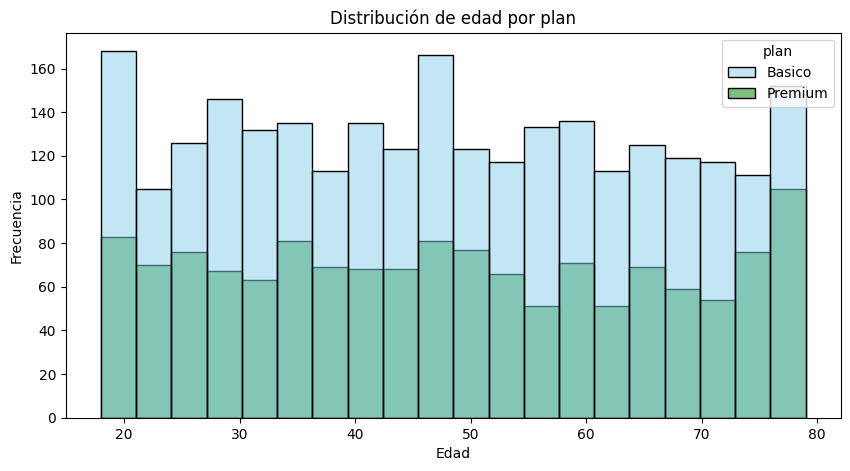

In [82]:
# Histograma para visualizar la edad
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20
)

plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

In [83]:
user_profile['plan'].value_counts()

Basico     2595
Premium    1405
Name: plan, dtype: int64

💡Insights: 

Distribución: Al revisar la gráfica, veo que hay clientes de diferentes edades, aproximadamente entre los 18 y los 80 años. Las edades están bastante repartidas y no noto que se concentren solamente en un grupo.

Comparación por plan: Al revisar los datos, encontré que el plan Básico tiene 2,595 clientes y el Premium 1,405. Esto significa que hay más usuarios del Básico en general, aunque en la gráfica también veo rangos de edad donde el Premium tiene bastante presencia. Por eso, no puedo decir que el Básico tenga más clientes en todas las edades.

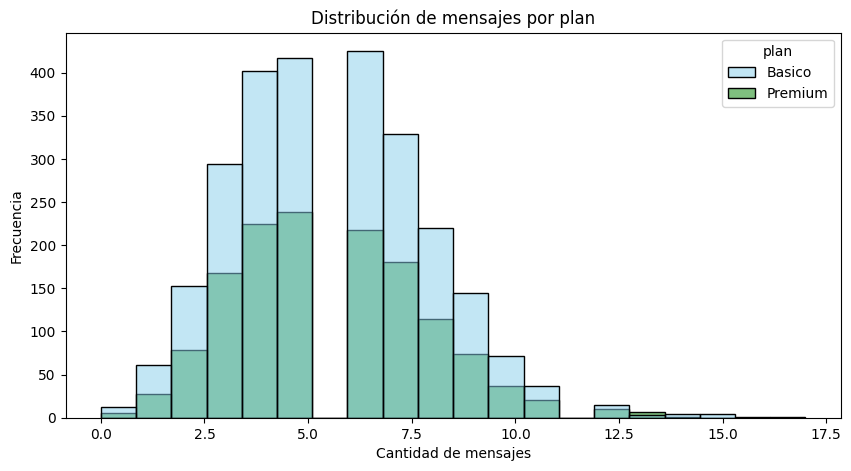

In [84]:
# Histograma para visualizar la cantidad de mensajes
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20
)

plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Frecuencia')
plt.show()

In [85]:
user_profile.groupby('plan')['cant_mensajes'].agg(
    clientes='count',
    promedio='mean',
    mediana='median',
    minimo='min',
    maximo='max'
).round(2)

,clientes,promedio,mediana,minimo,maximo
plan,,,,,
Basico,2594,5.53,5.0,0.0,17.0
Premium,1405,5.52,5.0,0.0,16.0


💡Insights: 

Distribución: Al revisar la gráfica y los resultados, veo que la mayoría de los clientes envía pocos mensajes. En los dos planes la mediana es de 5 mensajes, aunque también hay usuarios que llegan a enviar 16 o 17.

Comparación por plan: Lo que me llamó la atención es que, aunque el plan Básico tiene más clientes, el promedio de mensajes es casi igual en los dos planes. En el Básico es de 5.53 y en el Premium de 5.52, así que realmente no hay mucha diferencia en la cantidad de mensajes que envían.

Conclusión: Por lo que veo, los clientes de ambos planes tienen un uso bastante parecido de los mensajes. Tener un plan Básico o Premium no parece marcar una gran diferencia en este caso.

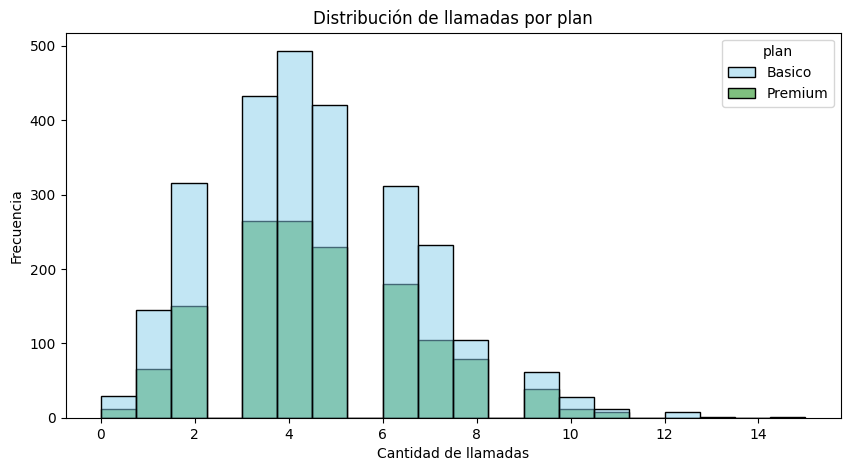

In [86]:
# Histograma para visualizar la cantidad de llamadas
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20
)

plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Frecuencia')
plt.show()

In [87]:
user_profile.groupby('plan')['cant_llamadas'].agg(
    clientes='count',
    promedio='mean',
    mediana='median',
    minimo='min',
    maximo='max'
).round(2)

,clientes,promedio,mediana,minimo,maximo
plan,,,,,
Basico,2594,4.46,4.0,0.0,15.0
Premium,1405,4.52,4.0,0.0,11.0


In [88]:
user_profile['plan'].value_counts()

Basico     2595
Premium    1405
Name: plan, dtype: int64

💡Insights: 

Distribución: Al revisar los resultados, veo que en ambos planes la mediana es de 4 llamadas. También hay clientes que no hacen ninguna llamada y otros que llegan hasta 15 en el Básico y 11 en el Premium.

Comparación por plan: Aunque el plan Básico tiene más clientes, el promedio de llamadas es casi igual en los dos planes. En el Básico es de 4.46 y en el Premium de 4.52. Me llamó la atención que el Premium tenga un promedio un poquito mayor, aunque la diferencia es muy pequeña.

Conclusión: Por lo que veo, los clientes de ambos planes hacen una cantidad de llamadas bastante parecida. No parece que tener un plan Básico o Premium haga una gran diferencia en este caso.

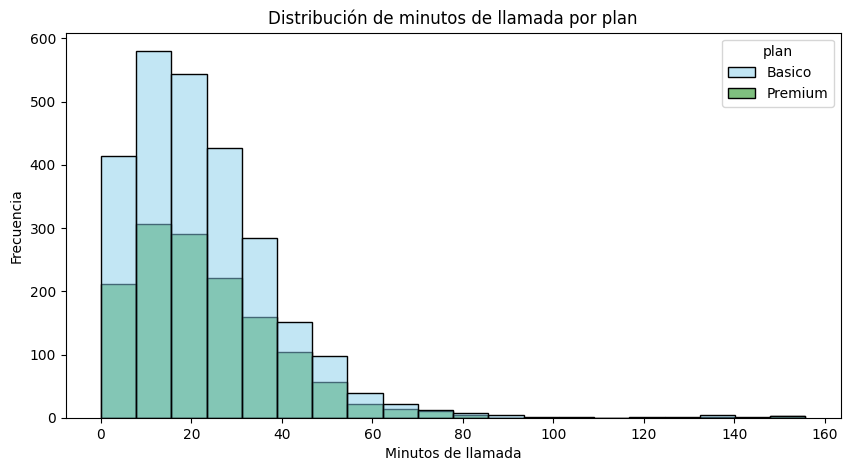

In [89]:
# Histograma para visualizar los minutos de llamada
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20
)

plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Frecuencia')
plt.show()


In [90]:
user_profile.groupby('plan')['cant_minutos_llamada'].agg(
    clientes='count',
    promedio='mean',
    mediana='median',
    minimo='min',
    maximo='max'
).round(2)

,clientes,promedio,mediana,minimo,maximo
plan,,,,,
Basico,2594,22.58,19.52,0.0,155.69
Premium,1405,23.31,20.30,0.0,153.06


💡Insights: 

Distribución: Al revisar los resultados, veo que la mayoría de los clientes acumula pocos minutos de llamadas. En ambos planes la mediana está cerca de los 20 minutos, aunque también hay usuarios que llegan a superar los 150 minutos. También noto que la distribución está sesgada a la derecha, porque hay pocos clientes que acumulan muchos más minutos que la mayoría.

Comparación por plan: Me doy cuenta de que los clientes del Premium acumulan un poquito más de minutos en promedio. En el Básico son 22.91 minutos y en el Premium 24.08. La diferencia no es muy grande, pero también se nota en la mediana, que es de 19.54 y 20.64 minutos.

Conclusión: Por lo que veo, los clientes de los dos planes tienen un uso bastante parecido en cuanto a minutos de llamadas. Aunque los del Premium hablan un poco más en promedio, no parece haber una diferencia muy marcada.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

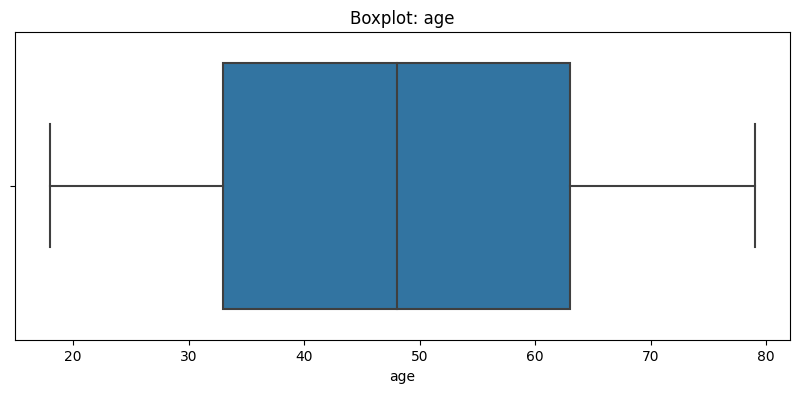

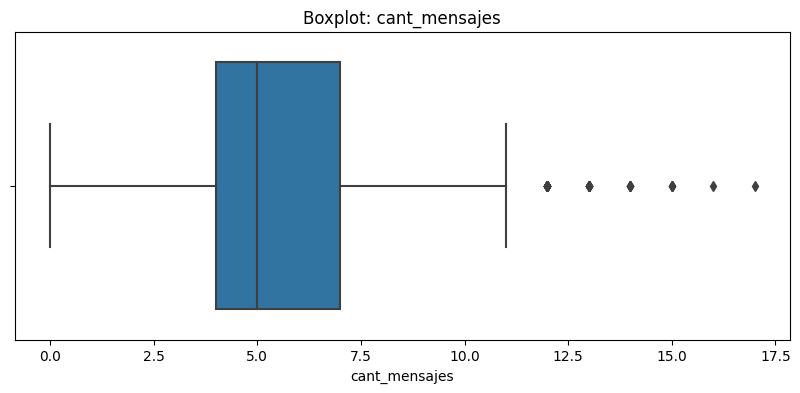

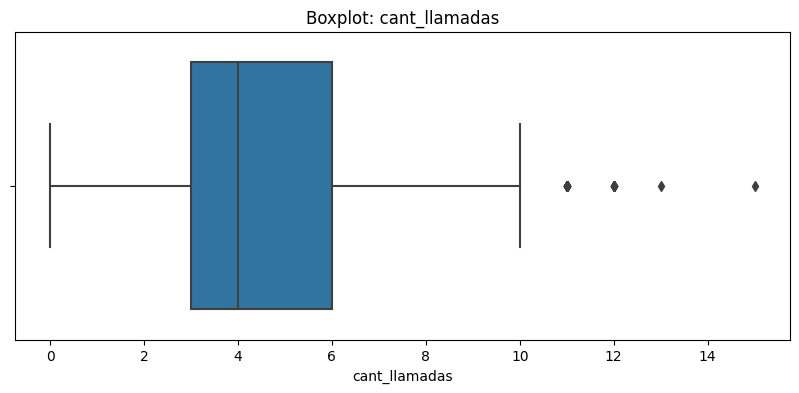

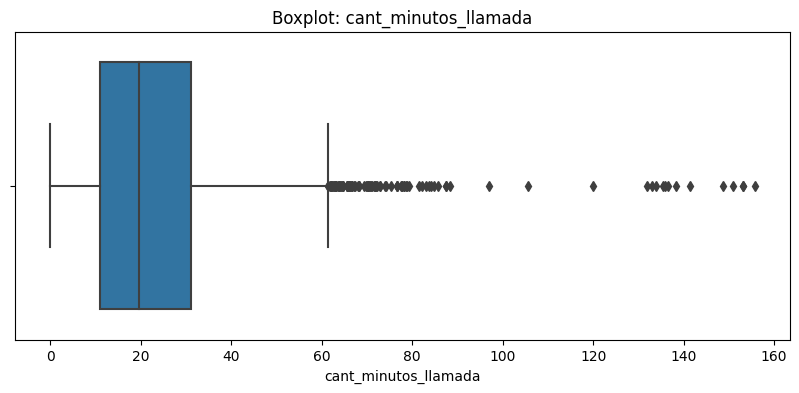

In [91]:
# Visualizando usando BoxPlot
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_numericas:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 

Edad: Al revisar la gráfica, veo que las edades van de los 18 a los 79 años. No encontré valores atípicos, así que no veo necesario hacer cambios.

Cantidad de mensajes: Aquí sí encontré algunos valores atípicos. La mayoría de los clientes envía entre 4 y 7 mensajes, pero algunos llegan hasta 17. Creo que esto puede ser normal, ya que no todos utilizan el servicio de la misma manera.

Cantidad de llamadas: También hay valores atípicos. La mayoría hace entre 3 y 6 llamadas, pero algunos llegan hasta 15. Esto me hace pensar que hay clientes que utilizan mucho más las llamadas que otros.

Minutos de llamada: Aquí fue donde más me llamó la atención la diferencia. La mediana es de 19.78 minutos, pero algunos clientes superan los 150 minutos. Es una diferencia bastante grande.

Conclusión: Por lo que veo, no eliminaría estos valores atípicos, porque pueden ser clientes que realmente utilizan más los servicios. Creo que también pueden ser útiles para ConectaTel, ya que permiten identificar a los usuarios que podrían necesitar planes con más beneficios.

In [92]:
# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'Variable: {col}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Valor máximo: {user_profile[col].max():.2f}')
    print()

Variable: cant_mensajes
Límite inferior: -0.50
Límite superior: 11.50
Valor máximo: 17.00

Variable: cant_llamadas
Límite inferior: -1.50
Límite superior: 10.50
Valor máximo: 15.00

Variable: cant_minutos_llamada
Límite inferior: -19.04
Límite superior: 61.32
Valor máximo: 155.69



In [93]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


💡Insights: 

cant_mensajes: Encontré algunos valores atípicos, ya que el límite es de 11.5 mensajes y hay clientes que llegan hasta 17. Yo los dejaría porque considero que es normal que algunas personas manden más mensajes que otras.

cant_llamadas: Aquí también encontré valores atípicos. El límite es de 10.5 llamadas y hay usuarios que llegan hasta 15. Yo también los mantendría porque no me parece una cantidad exagerada y puede ser parte del uso normal de algunos clientes.

cant_minutos_llamada: En este caso sí me llamó la atención la diferencia, porque el límite es de 61.32 minutos y hay clientes que llegan hasta 155.69. Antes de eliminarlos, revisaría si esos datos son correctos. Si no hay ningún error, los dejaría porque puede haber personas que utilizan mucho más el servicio.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [94]:
# Crear columna grupo_uso

def clasificar_uso(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']
    
    if pd.isna(llamadas) or pd.isna(mensajes):
        return 'Sin datos'

    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)


In [95]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [96]:
# Crear columna grupo_edad

def clasificar_edad(row):
    edad = row['age']

    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [97]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

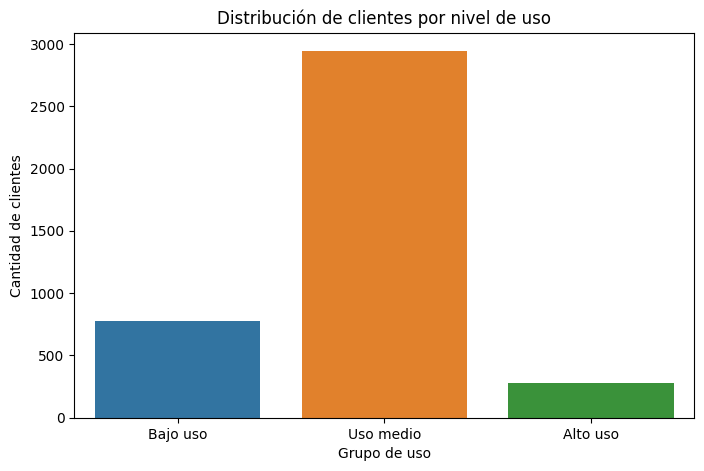

In [98]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.show()

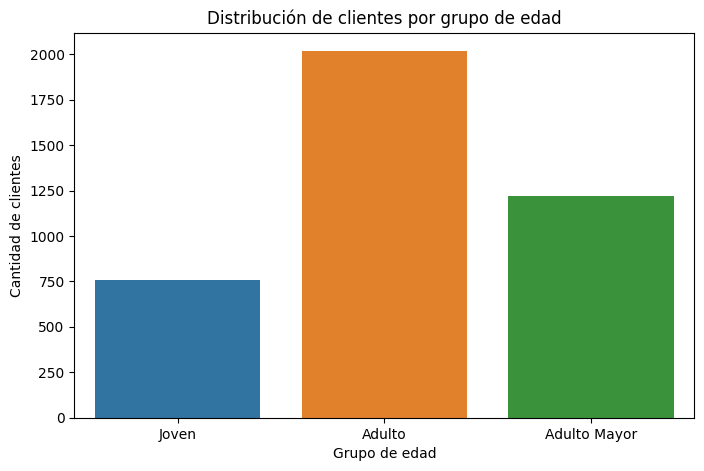

In [99]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor']
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.show()


In [100]:
print("CLIENTES POR GRUPO DE EDAD")
print(user_profile['grupo_edad'].value_counts(dropna=False))

print("\nCLIENTES POR NIVEL DE USO")
print(user_profile['grupo_uso'].value_counts(dropna=False))

CLIENTES POR GRUPO DE EDAD
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

CLIENTES POR NIVEL DE USO
Uso medio    2943
Bajo uso      778
Alto uso      278
Sin datos       1
Name: grupo_uso, dtype: int64


In [101]:
# Comparar los grupos de edad con los niveles de uso
pd.crosstab(
    user_profile['grupo_edad'],
    user_profile['grupo_uso']
)

grupo_uso,Alto uso,Bajo uso,Sin datos,Uso medio
grupo_edad,,,,
Adulto,153,364,1,1500
Adulto Mayor,74,257,0,891
Joven,51,157,0,552



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 

- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

Al revisar los datos encontré algunos problemas que necesitaban corregirse. Por ejemplo, en la columna age había valores de -999, que no corresponden a una edad real, y en city había registros con ?.

También encontré 40 clientes con fechas de registro de 2026, aunque los datos que estamos analizando llegan hasta 2024. Esto representa el 1% de los 4,000 clientes.

En la tabla usage había 50 registros sin fecha, de un total de 40,000, lo que representa el 0.125%.

Otro problema fueron los valores faltantes en duration y length, pero al revisarlos observé que muchos se relacionaban con el tipo de servicio, ya que las llamadas tienen duración y los mensajes tienen longitud.

Creo que fue importante revisar estos problemas antes de comenzar el análisis para evitar resultados incorrectos.

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

Dividí a los clientes en tres grupos de edad: jóvenes, adultos y adultos mayores.

Encontré que el grupo más grande es el de adultos, con 2,018 clientes (50.45%), seguido de los adultos mayores, con 1,222 (30.55%), y los jóvenes, con 760 (19%).

También clasifiqué a los clientes por su nivel de uso. La mayoría tiene un uso medio, con 2,943 clientes (73.58%). Después están los de bajo uso, con 778 (19.45%), y finalmente los de alto uso, con 278 (6.95%). Un cliente quedó sin clasificar porque no tenía datos suficientes.

Al comparar los grupos de edad con los niveles de uso, observé que en los tres grupos predomina el uso medio.

Esto me hace pensar que la edad, por sí sola, no determina cuánto utilizan los clientes el servicio.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

Encontré algunos clientes que tienen un consumo mucho más alto que la mayoría.

En mensajes, el límite superior calculado fue de 11.5 y el máximo llegó a 17. En llamadas, el límite fue de 10.5 y el máximo fue de 15.

En los minutos de llamada encontré una diferencia mayor, ya que el límite superior fue de 61.32 minutos y había clientes con consumos de hasta 155.69 minutos.

Considero que no sería correcto eliminar estos registros sin revisarlos primero, porque podrían ser clientes que realmente utilizan mucho el servicio.

Para ConectaTel, estos casos pueden ser importantes porque permiten identificar clientes con necesidades diferentes y evaluar si los planes actuales son suficientes para ellos.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

Yo recomendaría que ConectaTel revisara qué tanto utilizan los servicios sus clientes antes de ofrecerles un plan.

Como la mayoría tiene un uso medio, considero que sería importante contar con planes que se adapten a ese tipo de consumo.

Para quienes utilizan poco el servicio, se podrían evaluar opciones más sencillas o económicas. Por otro lado, para los clientes de alto uso se podrían considerar planes con mayores beneficios.

También revisaría si los clientes realmente están aprovechando lo que incluye su plan actual.

Finalmente, antes de hacer cambios, analizaría cuánto paga cada segmento y cuánto le cuesta a la empresa atenderlo. Así las decisiones no se basarían solamente en cuánto consumen los clientes.

✍️ **Escribe aquí tu análisis ejecutivo:**

⚠️ **Problemas detectados en los datos**

Al revisar los datos encontré algunos problemas que necesitaban corregirse, como edades con valores de -999, ciudades registradas como ?, 40 clientes con fechas fuera del periodo de análisis (1%) y 50 registros de uso sin fecha (0.125%).

También había valores faltantes en duración y longitud, aunque muchos se explican porque las llamadas y los mensajes registran información diferente.

🔍 **Segmentos por Edad**

El grupo más grande es el de adultos, con 2,018 clientes (50.45%). Después están los adultos mayores, con 1,222 (30.55%), y los jóvenes, con 760 (19%).

Al comparar las edades con los niveles de uso, observé que en los tres grupos predomina el uso medio. Esto me hace pensar que no sería conveniente ofrecer planes basándose solamente en la edad.

📊 **Segmentos por Nivel de Uso**

La mayoría de los clientes tiene un uso medio, con 2,943 usuarios (73.58%). También encontré 778 clientes de bajo uso (19.45%), 278 de alto uso (6.95%) y uno sin datos suficientes para clasificarlo.

Al comparar los planes Básico y Premium, observé que el promedio de mensajes y llamadas es bastante parecido. Los clientes Premium utilizan ligeramente más minutos de llamada, pero la diferencia no es muy grande.

➡️ Esto sugiere que...

ConectaTel tiene una base importante de clientes con necesidades de consumo moderadas, por lo que sería conveniente revisar si los planes actuales se adaptan a ellos.

También encontré clientes con consumos mucho más altos, especialmente en minutos de llamada, donde algunos llegaron a 155.69 minutos.

Considero que estos casos deben revisarse antes de eliminarlos, porque podrían representar necesidades reales de algunos clientes.

💡 **Recomendaciones**

Recomendaría revisar si los planes actuales se ajustan al consumo de los clientes.

Se podrían considerar opciones más sencillas para quienes utilizan poco el servicio y planes con mayores beneficios para los clientes de alto uso.

También analizaría los ingresos y costos de cada segmento antes de implementar cambios, para asegurar que las propuestas sean convenientes tanto para los clientes como para ConectaTel.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`